# Notebook 01 — Dataset Understanding and Audit


## 1. Imports 

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import hashlib
import random
import warnings
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile, UnidentifiedImageError
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ImageFile.LOAD_TRUNCATED_IMAGES = False
warnings.filterwarnings("default")

print("Imports completed.")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)


Imports completed.
Pandas: 3.0.6
NumPy: 2.4.6


## 2. Configure the project and dataset paths


In [ ]:

CWD = Path.cwd().resolve()
if CWD.name.lower() == "notebooks":
    PROJECT_ROOT = CWD.parent
else:
   
    PROJECT_ROOT = CWD

DEFAULT_DATASET_ROOT = PROJECT_ROOT / "data" / "raw"

DATASET_ROOT = DEFAULT_DATASET_ROOT / "dataset_new"

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "dataset_audit"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_CLASSES = ["Closed", "Open", "no_yawn", "yawn"]
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

print("Current working directory:", CWD)
print("Project root:", PROJECT_ROOT)
print("Dataset root:", DATASET_ROOT)
print("Audit output directory:", OUTPUT_DIR)

if not DATASET_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATASET_ROOT}\n"
        "Extract archive.zip into data/raw/, or update DATASET_ROOT in this cell."
    )


Current working directory: D:\driver drowsiness detection final\notebooks
Project root: D:\driver drowsiness detection final
Dataset root: D:\driver drowsiness detection final\data\raw\dataset_new
Audit output directory: D:\driver drowsiness detection final\outputs\dataset_audit


## 3. Detect the dataset


In [3]:
def direct_class_dirs(folder: Path):
    if not folder.is_dir():
        return set()
    return {
        p.name for p in folder.iterdir()
        if p.is_dir() and p.name in EXPECTED_CLASSES
    }

if direct_class_dirs(DATASET_ROOT / "train") or direct_class_dirs(DATASET_ROOT / "test"):
    SPLIT_DIRS = {
        split: DATASET_ROOT / split
        for split in ["train", "validation", "val", "test"]
        if (DATASET_ROOT / split).is_dir()
    }
    LAYOUT = "split"
elif direct_class_dirs(DATASET_ROOT):
    SPLIT_DIRS = {"all": DATASET_ROOT}
    LAYOUT = "class_folders_at_root"
else:
    children = [p.name for p in DATASET_ROOT.iterdir() if p.is_dir()]
    raise ValueError(
        "Could not identify expected class folders.\n"
        f"Folders directly under dataset root: {children}\n"
        f"Expected class folders: {EXPECTED_CLASSES}\n"
        "Update DATASET_ROOT or adapt the expected class names to match the archive."
    )

print("Detected layout:", LAYOUT)
print("Detected data folders:")
for name, path in SPLIT_DIRS.items():
    print(f"  {name}: {path}")


Detected layout: split
Detected data folders:
  train: D:\driver drowsiness detection final\data\raw\dataset_new\train
  test: D:\driver drowsiness detection final\data\raw\dataset_new\test


## 4. Count files and check class balance


In [4]:
count_rows = []
for split_name, split_path in SPLIT_DIRS.items():
    for class_name in EXPECTED_CLASSES:
        class_dir = split_path / class_name
        files = [
            p for p in class_dir.rglob("*")
            if p.is_file() and p.suffix.lower() in SUPPORTED_EXTENSIONS
        ] if class_dir.exists() else []
        count_rows.append({
            "split": split_name,
            "class": class_name,
            "image_count": len(files),
            "class_folder_exists": class_dir.exists()
        })

counts_df = pd.DataFrame(count_rows)
display(counts_df)

counts_csv = OUTPUT_DIR / "class_counts.csv"
counts_df.to_csv(counts_csv, index=False)
print("Saved:", counts_csv)

for split_name, group in counts_df.groupby("split", sort=False):
    total = int(group["image_count"].sum())
    print(f"\n{split_name}: {total:,} images")
    if total:
        display(
            group[["class", "image_count"]]
            .assign(percent=lambda x: (100 * x["image_count"] / total).round(2))
        )

missing_folders = counts_df.loc[~counts_df["class_folder_exists"], ["split", "class"]]
if not missing_folders.empty:
    print("\nWARNING: Some expected class folders are missing:")
    display(missing_folders)


,split,class,image_count,class_folder_exists
0,train,Closed,617,True
1,train,Open,617,True
2,train,no_yawn,616,True
3,train,yawn,617,True
4,test,Closed,109,True
5,test,Open,109,True
6,test,no_yawn,109,True
7,test,yawn,106,True


Saved: D:\driver drowsiness detection final\outputs\dataset_audit\class_counts.csv

train: 2,467 images


,class,image_count,percent
0,Closed,617,25.01
1,Open,617,25.01
2,no_yawn,616,24.97
3,yawn,617,25.01



test: 433 images


,class,image_count,percent
4,Closed,109,25.17
5,Open,109,25.17
6,no_yawn,109,25.17
7,yawn,106,24.48


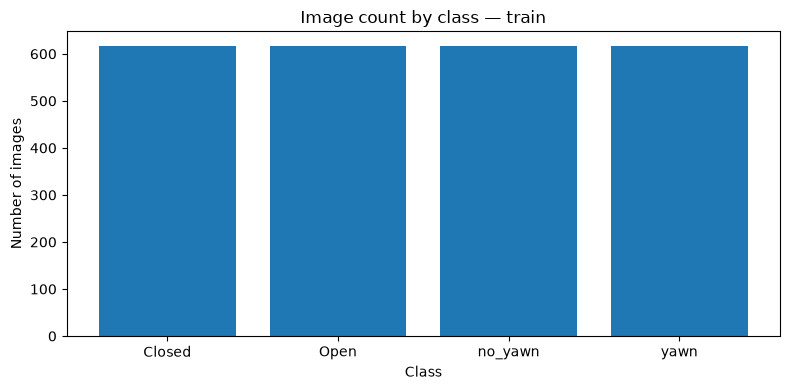

Saved: D:\driver drowsiness detection final\outputs\dataset_audit\class_distribution_train.png


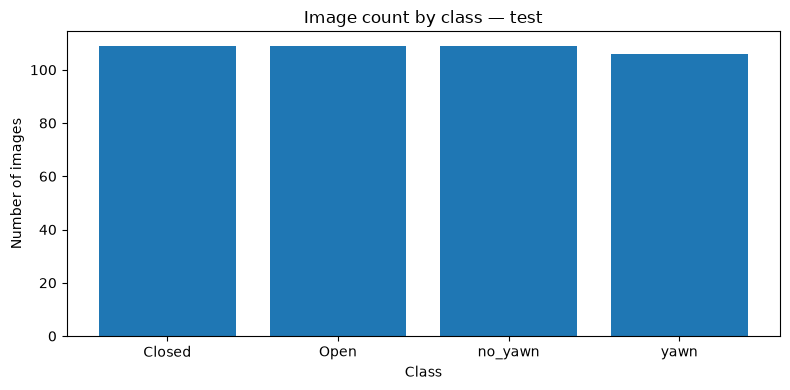

Saved: D:\driver drowsiness detection final\outputs\dataset_audit\class_distribution_test.png


In [5]:
# Visualize counts per split.
for split_name, group in counts_df.groupby("split", sort=False):
    plt.figure(figsize=(8, 4))
    plt.bar(group["class"], group["image_count"])
    plt.title(f"Image count by class — {split_name}")
    plt.xlabel("Class")
    plt.ylabel("Number of images")
    plt.tight_layout()
    plot_path = OUTPUT_DIR / f"class_distribution_{split_name}.png"
    plt.savefig(plot_path, dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved:", plot_path)


## 5. Build a file-level manifest and inspect image dimensions


In [6]:
records = []
for split_name, split_path in SPLIT_DIRS.items():
    for class_name in EXPECTED_CLASSES:
        class_dir = split_path / class_name
        if not class_dir.exists():
            continue
        for path in sorted(class_dir.rglob("*")):
            if not path.is_file():
                continue

            record = {
                "split": split_name,
                "class": class_name,
                "relative_path": str(path.relative_to(PROJECT_ROOT))
                    if path.is_relative_to(PROJECT_ROOT) else str(path),
                "absolute_path": str(path.resolve()),
                "extension": path.suffix.lower(),
                "file_size_bytes": path.stat().st_size,
                "width": None,
                "height": None,
                "mode": None,
                "readable": False,
                "sha256": None,
                "error": None
            }

            if path.suffix.lower() not in SUPPORTED_EXTENSIONS:
                record["error"] = "Unsupported or non-image extension"
                records.append(record)
                continue

            try:
                digest = hashlib.sha256()
                with path.open("rb") as f:
                    for chunk in iter(lambda: f.read(1024 * 1024), b""):
                        digest.update(chunk)
                record["sha256"] = digest.hexdigest()

                with Image.open(path) as img:
                    img.verify()

                # Re-open after verify to inspect metadata.
                with Image.open(path) as img:
                    record["width"], record["height"] = img.size
                    record["mode"] = img.mode
                    record["readable"] = True

            except (UnidentifiedImageError, OSError, ValueError, SyntaxError) as exc:
                record["error"] = f"{type(exc).__name__}: {exc}"

            records.append(record)

manifest_df = pd.DataFrame(records)
manifest_path = OUTPUT_DIR / "image_manifest.csv"
manifest_df.to_csv(manifest_path, index=False)

print(f"Files inspected: {len(manifest_df):,}")
print(f"Readable supported images: {int(manifest_df['readable'].sum()):,}")
print(f"Unsupported/non-image files: {int((manifest_df['error'] == 'Unsupported or non-image extension').sum()):,}")
print("Saved:", manifest_path)

display(manifest_df.head(10))


Files inspected: 2,900
Readable supported images: 2,900
Unsupported/non-image files: 0
Saved: D:\driver drowsiness detection final\outputs\dataset_audit\image_manifest.csv


,split,class,relative_path,absolute_path,extension,file_size_bytes,width,height,mode,readable,sha256,error
0,train,Closed,data\raw\dataset_new\train\Closed\_0.jpg,D:\driver drowsiness detection final\data\raw\...,.jpg,6237,145,145,RGB,True,64e34b235eb098307fbd07ed6efdd7e4b42afcef0d1c53...,None
1,train,Closed,data\raw\dataset_new\train\Closed\_1.jpg,D:\driver drowsiness detection final\data\raw\...,.jpg,10383,142,135,RGB,True,6d54fcab3f80f40acfab1c6721cbfb26210cc1f1ca6711...,None
2,train,Closed,data\raw\dataset_new\train\Closed\_10.jpg,D:\driver drowsiness detection final\data\raw\...,.jpg,25882,131,127,RGB,True,760d927cc87c0e000aaea8f5ee9876e667f3ad4a5a2567...,None
3,train,Closed,data\raw\dataset_new\train\Closed\_100.jpg,D:\driver drowsiness detection final\data\raw\...,.jpg,17495,288,287,RGB,True,cc243fcdbe524eed74e4f93cdd420ecb832d24d8d09011...,None
4,train,Closed,data\raw\dataset_new\train\Closed\_101.jpg,D:\driver drowsiness detection final\data\raw\...,.jpg,26806,141,123,RGB,True,141f42583b963a61bd28b6f339498706c211dd75f0785c...,None
5,train,Closed,data\raw\dataset_new\train\Closed\_102.jpg,D:\driver drowsiness detection final\data\raw\...,.jpg,29698,179,164,RGB,True,edb3fed1d353c7db8eb4d1eb6a1ba228a9cc15770b5f8e...,None
6,train,Closed,data\raw\dataset_new\train\Closed\_103.jpg,D:\driver drowsiness detection final\data\raw\...,.jpg,26532,142,166,RGB,True,67c57a1b3bc41351d59a10b5e8fc04690f7e4560208929...,None
7,train,Closed,data\raw\dataset_new\train\Closed\_104.jpg,D:\driver drowsiness detection final\data\raw\...,.jpg,27883,138,139,RGB,True,2f05bba597c434156dd913e35982c7e281d2e7399d9cab...,None
8,train,Closed,data\raw\dataset_new\train\Closed\_105.jpg,D:\driver drowsiness detection final\data\raw\...,.jpg,28046,154,139,RGB,True,d8a3bc3920353a1cca2ed5ac327bea9f67b22c02962283...,None
9,train,Closed,data\raw\dataset_new\train\Closed\_106.jpg,D:\driver drowsiness detection final\data\raw\...,.jpg,27633,200,150,RGB,True,027f01816ce3a8b9b639e197e56106d31d1fabcfae0f35...,None


In [7]:
# Summary of dimensions, modes, and formats among readable images.
readable_df = manifest_df[manifest_df["readable"]].copy()

if readable_df.empty:
    print("No readable images found. Check the dataset path and file formats.")
else:
    readable_df["dimensions"] = (
        readable_df["width"].astype(int).astype(str)
        + "x"
        + readable_df["height"].astype(int).astype(str)
    )
    print("Most common dimensions:")
    display(readable_df["dimensions"].value_counts().head(15).rename_axis("dimensions").reset_index(name="count"))

    print("Image formats/extensions:")
    display(readable_df["extension"].value_counts().rename_axis("extension").reset_index(name="count"))

    print("Color modes:")
    display(readable_df["mode"].value_counts().rename_axis("mode").reset_index(name="count"))

    print("Image dimension statistics:")
    display(readable_df[["width", "height"]].describe().round(2))


Most common dimensions:


,dimensions,count
0,640x480,1448
1,300x300,14
2,342x300,9
3,390x300,7
4,370x300,7
5,314x300,6
6,400x300,6
7,323x300,6
8,300x306,6
9,304x300,6


Image formats/extensions:


,extension,count
0,.jpg,2900


Color modes:


,mode,count
0,RGB,2898
1,RGBA,2


Image dimension statistics:


,width,height
count,2900.00,2900.00
mean,490.29,396.78
std,219.07,177.41
min,50.00,40.00
25%,304.00,300.00
50%,640.00,480.00
75%,640.00,480.00
max,1625.00,1625.00


## 6. Check unreadable images and other files


In [8]:
unreadable_df = manifest_df[~manifest_df["readable"]].copy()
unreadable_path = OUTPUT_DIR / "unreadable_or_unsupported_files.csv"
unreadable_df.to_csv(unreadable_path, index=False)

if unreadable_df.empty:
    print("PASS: All files with supported image extensions were readable.")
else:
    print(f"WARNING: {len(unreadable_df)} files were unreadable or unsupported.")
    display(unreadable_df[["split", "class", "absolute_path", "extension", "error"]].head(50))

print("Saved:", unreadable_path)


PASS: All files with supported image extensions were readable.
Saved: D:\driver drowsiness detection final\outputs\dataset_audit\unreadable_or_unsupported_files.csv


## 7. Display representative images from each class



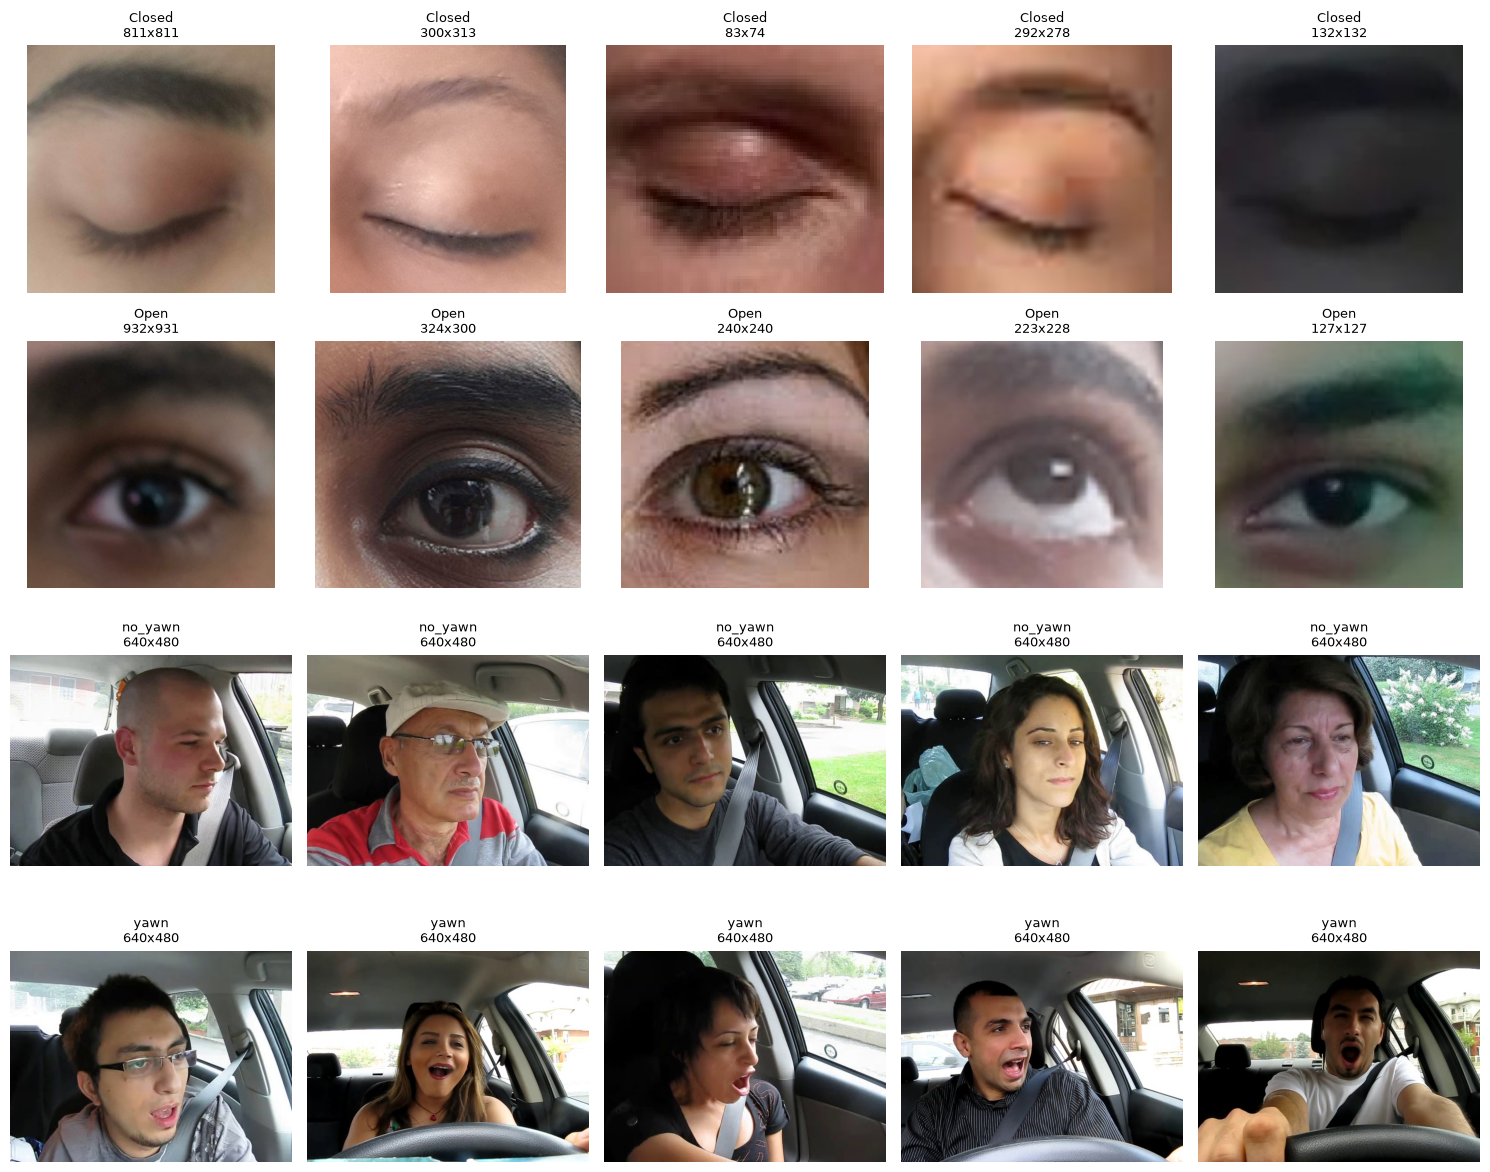

Saved: D:\driver drowsiness detection final\outputs\dataset_audit\representative_samples.png


In [9]:
def show_class_samples(manifest: pd.DataFrame, samples_per_class: int = 5):
    valid = manifest[manifest["readable"]].copy()
    if valid.empty:
        print("No readable images available to display.")
        return

    fig, axes = plt.subplots(
        len(EXPECTED_CLASSES), samples_per_class,
        figsize=(3 * samples_per_class, 3 * len(EXPECTED_CLASSES)),
        squeeze=False
    )

    for row, class_name in enumerate(EXPECTED_CLASSES):
        class_df = valid[valid["class"] == class_name]
        selected = class_df.sample(
            n=min(samples_per_class, len(class_df)),
            random_state=SEED
        ) if not class_df.empty else class_df

        for col in range(samples_per_class):
            ax = axes[row, col]
            ax.axis("off")
            if col >= len(selected):
                continue

            item = selected.iloc[col]
            try:
                with Image.open(item["absolute_path"]) as img:
                    ax.imshow(img.convert("RGB"))
                ax.set_title(
                    f"{class_name}\n{int(item['width'])}x{int(item['height'])}",
                    fontsize=9
                )
            except Exception as exc:
                ax.set_title(f"Could not display\n{type(exc).__name__}")

    plt.tight_layout()
    sample_path = OUTPUT_DIR / "representative_samples.png"
    plt.savefig(sample_path, dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved:", sample_path)

show_class_samples(manifest_df, samples_per_class=5)


## 8. Detect exact duplicates


In [10]:
hash_df = manifest_df[
    manifest_df["readable"] & manifest_df["sha256"].notna()
].copy()

duplicate_rows = []
for digest, group in hash_df.groupby("sha256"):
    if len(group) > 1:
        duplicate_rows.append(group.assign(duplicate_group=digest[:12]))

if duplicate_rows:
    duplicates_df = pd.concat(duplicate_rows, ignore_index=True)
    duplicates_path = OUTPUT_DIR / "exact_duplicates.csv"
    duplicates_df.to_csv(duplicates_path, index=False)
    print(f"WARNING: Found {len(duplicates_df)} files in exact-duplicate groups.")
    display(duplicates_df[["duplicate_group", "split", "class", "absolute_path"]].head(100))
    print("Saved:", duplicates_path)
else:
    duplicates_df = pd.DataFrame()
    duplicates_path = OUTPUT_DIR / "exact_duplicates.csv"
    duplicates_df.to_csv(duplicates_path, index=False)
    print("PASS: No exact duplicate file contents found among readable images.")
    print("Saved empty report:", duplicates_path)

if LAYOUT == "split" and not hash_df.empty:
    # Treat train and validation as development data; test is held out.
    dev_names = {"train", "validation", "val"}
    dev_hashes = set(hash_df.loc[hash_df["split"].isin(dev_names), "sha256"])
    test_hashes = set(hash_df.loc[hash_df["split"] == "test", "sha256"])
    overlap = dev_hashes & test_hashes
    print(f"Exact hashes shared between development splits and test: {len(overlap)}")
    if overlap:
        leakage_df = hash_df[hash_df["sha256"].isin(overlap)].copy()
        leakage_path = OUTPUT_DIR / "train_test_exact_overlap.csv"
        leakage_df.to_csv(leakage_path, index=False)
        display(leakage_df[["split", "class", "sha256", "absolute_path"]].head(100))
        print("WARNING: Review these overlaps before evaluation. Saved:", leakage_path)
    else:
        print("PASS: No exact-content overlap detected between development and test sets.")


PASS: No exact duplicate file contents found among readable images.
Saved empty report: D:\driver drowsiness detection final\outputs\dataset_audit\exact_duplicates.csv
Exact hashes shared between development splits and test: 0
PASS: No exact-content overlap detected between development and test sets.


## 9. Check label distribution


In [11]:
if not counts_df.empty:
    task_map = {
        "Eye-state task": ["Closed", "Open"],
        "Mouth-state task": ["no_yawn", "yawn"]
    }
    task_rows = []
    for split_name, group in counts_df.groupby("split", sort=False):
        count_map = dict(zip(group["class"], group["image_count"]))
        for task_name, classes in task_map.items():
            a, b = classes
            ca, cb = int(count_map.get(a, 0)), int(count_map.get(b, 0))
            total = ca + cb
            task_rows.append({
                "split": split_name,
                "task": task_name,
                f"{a}_count": ca,
                f"{b}_count": cb,
                "total": total,
                "minority_class_percent": round(100 * min(ca, cb) / total, 2) if total else None
            })
    task_balance_df = pd.DataFrame(task_rows)
    display(task_balance_df)
    task_balance_path = OUTPUT_DIR / "binary_task_counts.csv"
    task_balance_df.to_csv(task_balance_path, index=False)
    print("Saved:", task_balance_path)


,split,task,Closed_count,Open_count,total,minority_class_percent,no_yawn_count,yawn_count
0,train,Eye-state task,617.0,617.0,1234,50.00,NaN,NaN
1,train,Mouth-state task,NaN,NaN,1233,49.96,616.0,617.0
2,test,Eye-state task,109.0,109.0,218,50.00,NaN,NaN
3,test,Mouth-state task,NaN,NaN,215,49.30,109.0,106.0


Saved: D:\driver drowsiness detection final\outputs\dataset_audit\binary_task_counts.csv


## 10. Generate an audit summary


In [12]:
supported_count = int(manifest_df["extension"].isin(SUPPORTED_EXTENSIONS).sum())
readable_count = int(manifest_df["readable"].sum())
unreadable_count = int(
    (manifest_df["extension"].isin(SUPPORTED_EXTENSIONS) & ~manifest_df["readable"]).sum()
)
unique_hash_count = int(hash_df["sha256"].nunique()) if not hash_df.empty else 0
duplicate_file_count = int(len(duplicates_df)) if not duplicates_df.empty else 0

summary = {
    "dataset_root": str(DATASET_ROOT.resolve()),
    "layout": LAYOUT,
    "expected_classes": EXPECTED_CLASSES,
    "splits_detected": list(SPLIT_DIRS.keys()),
    "supported_image_files": supported_count,
    "readable_images": readable_count,
    "unreadable_supported_images": unreadable_count,
    "unique_sha256_hashes": unique_hash_count,
    "files_in_exact_duplicate_groups": duplicate_file_count,
    "class_counts_csv": str(counts_csv),
    "image_manifest_csv": str(manifest_path),
    "output_directory": str(OUTPUT_DIR.resolve())
}

summary_df = pd.DataFrame([{
    "item": key,
    "value": json.dumps(value) if isinstance(value, (list, dict)) else value
} for key, value in summary.items()])
display(summary_df)

summary_path = OUTPUT_DIR / "audit_summary.csv"
summary_df.to_csv(summary_path, index=False)
print("Saved:", summary_path)
print("\nAudit completed. Review the warnings and representative image grid before proceeding.")


,item,value
0,dataset_root,D:\driver drowsiness detection final\data\raw\...
1,layout,split
2,expected_classes,"[""Closed"", ""Open"", ""no_yawn"", ""yawn""]"
3,splits_detected,"[""train"", ""test""]"
4,supported_image_files,2900
5,readable_images,2900
6,unreadable_supported_images,0
7,unique_sha256_hashes,2900
8,files_in_exact_duplicate_groups,0
9,class_counts_csv,D:\driver drowsiness detection final\outputs\d...


Saved: D:\driver drowsiness detection final\outputs\dataset_audit\audit_summary.csv

Audit completed. Review the warnings and representative image grid before proceeding.
